<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Recovery changes the evidence population

**How does deleted-record recovery change what a Registry-hive query returns?**
We will inventory every supplied input, distinguish a dirty header from malformed
bytes, inspect typed values with SQL, and keep recovered rows separate from
allocated values.

Three synthetic Registry hives, two invalid byte inputs and one missing-input record
contain no real machine or account data. The files are test cases, not observations
of a running Windows system. No credentials are decoded. Example path strings are
inert fixture text and are never executed.

## Choose the recovery scope

`RECOVER_DELETED=False` scans allocated content. Set it to `True` in the closing
experiment to include the parser's deleted-record recovery. Both modes explicitly
set `apply_logs:=false`; these fixtures have no transaction-log files. Restart the
kernel and run all after changing the boolean.

In [1]:
RECOVER_DELETED = False

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_support import finish, prose, theme

if type(RECOVER_DELETED) is not bool:
    raise ValueError("RECOVER_DELETED must be True or False.")
audit = summary = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-reghive/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-reghive/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-reghive/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-reghive/notebooks/pyproject.toml.

## Attach a published worker and keep the input denominator

The literal native release location requires no Rust build. `read_blob` loads the
bundled bytes before any table scan, so malformed and missing inputs cannot disappear
from the audit. The SQL NULL represents an absent input, while the empty file is a
supplied zero-byte input. All later file paths are relative to this notebook directory.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'reghive' (TYPE vgi,LOCATION 'github-auto://Query-farm/vgi-reghive@v0.4.0');
CREATE TABLE inputs AS
 SELECT filename AS source,regexp_extract(filename,'([^/]+)$',1) AS input_id,content
 FROM read_blob(['fixtures/*.hve','fixtures/*.bin'])
 UNION ALL SELECT NULL,'missing',NULL;
SELECT input_id,octet_length(content) AS supplied_bytes FROM inputs ORDER BY input_id;

,input_id,supplied_bytes
0,empty.bin,0
1,garbage.bin,38
2,missing,<NA>
3,software.hve,12288
4,system_clean.hve,12288
5,system_dirty.hve,12288


## Inspect base-block health separately from recovery

`well_formed` and `hive_info` are scalar probes over the byte column. A dirty hive
has mismatched sequence numbers; it can still have a recognized, well-formed header.
These header probes do not certify every cell or establish that an acquisition is
complete. `logs_applied` receives explicitly absent logs here. Its zero replay count
is an observation about these inputs, not evidence that no transactions are missing.

In [4]:
%%sql
CREATE TABLE probes AS SELECT *,
 reghive.main.well_formed(content) AS validity,
 reghive.main.hive_info(content) AS header,
 reghive.main.logs_applied(content,NULL::BLOB,NULL::BLOB) AS log_info
FROM inputs;
CREATE TABLE input_audit AS SELECT source,input_id,octet_length(content) AS supplied_bytes,
 validity.ok AS header_ok,validity.kind AS validation_kind,
 header.hive_type AS hive_type,header.primary_seq AS primary_seq,
 header.secondary_seq AS secondary_seq,header.is_dirty AS is_dirty,
 log_info.applied AS logs_applied,log_info.entries_replayed AS entries_replayed,
 CASE WHEN content IS NULL THEN 'Missing input'
 WHEN octet_length(content)=0 THEN 'Empty input'
 WHEN NOT validity.ok THEN 'Malformed header'
 WHEN header.is_dirty THEN 'Dirty header, no logs'
 ELSE 'Clean header' END AS input_state
FROM probes;
SELECT * EXCLUDE(source) FROM input_audit ORDER BY input_id;

,input_id,supplied_bytes,header_ok,validation_kind,hive_type,primary_seq,secondary_seq,is_dirty,logs_applied,entries_replayed,input_state
0,empty.bin,0,False,truncated,None,<NA>,<NA>,<NA>,<NA>,<NA>,Empty input
1,garbage.bin,38,False,bad-signature,None,<NA>,<NA>,<NA>,<NA>,<NA>,Malformed header
2,missing,<NA>,<NA>,None,None,<NA>,<NA>,<NA>,<NA>,<NA>,Missing input
3,software.hve,12288,True,ok,SOFTWARE,1,1,False,False,0,Clean header
4,system_clean.hve,12288,True,ok,SYSTEM,1,1,False,False,0,Clean header
5,system_dirty.hve,12288,True,ok,SYSTEM,2,1,True,False,0,"Dirty header, no logs"


In [5]:
%%sql audit <<
SELECT input_id,input_state,supplied_bytes,header_ok,is_dirty,logs_applied,entries_replayed
FROM input_audit ORDER BY input_id;

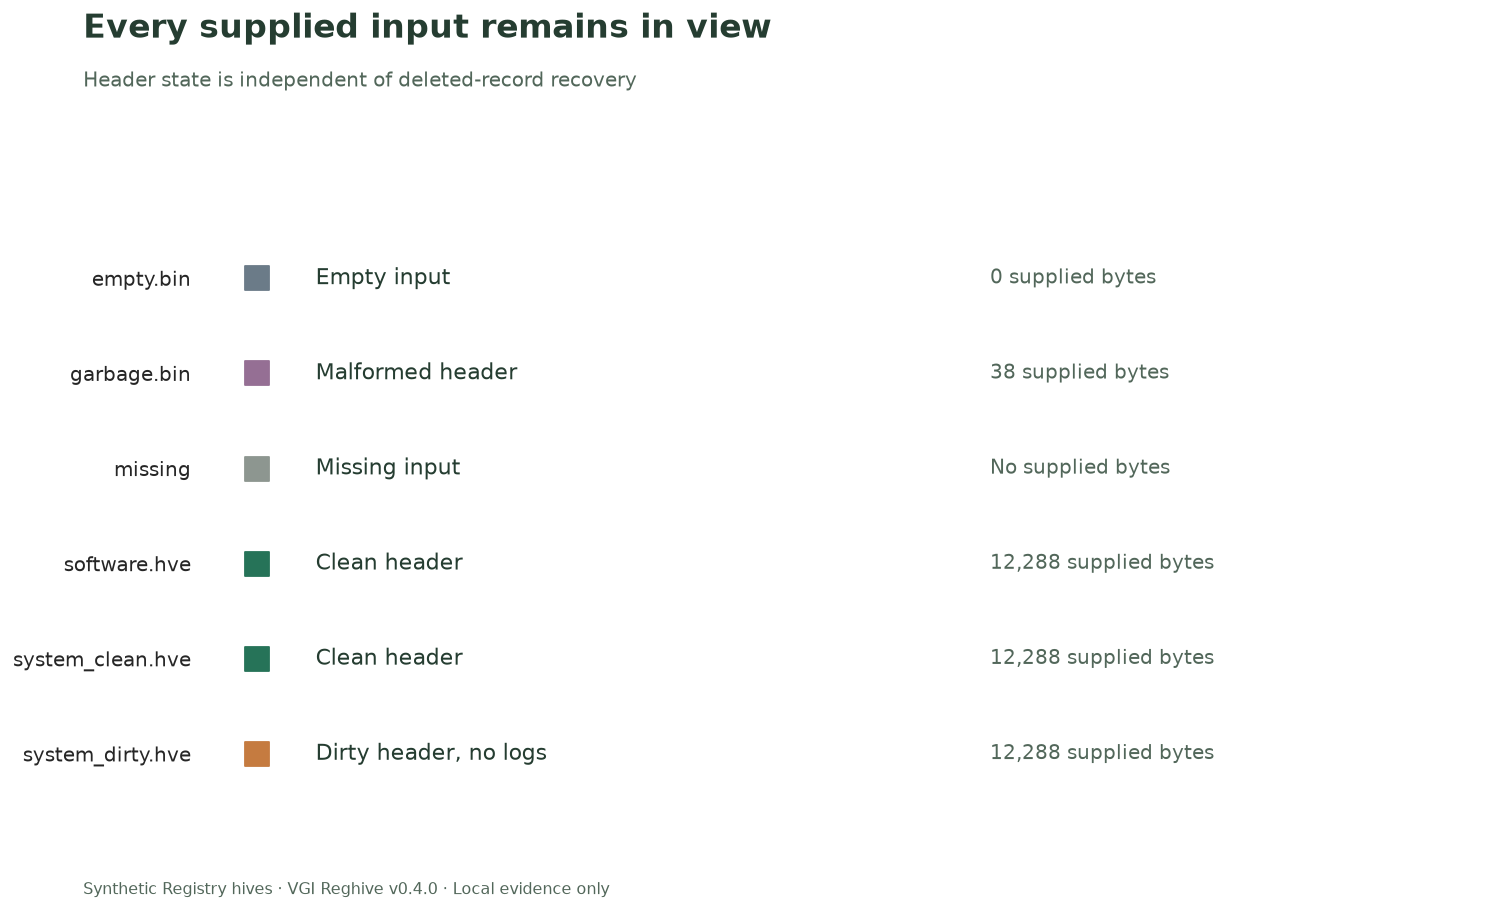

The audit preserves **6 inputs**, including **3 recognized headers**. The dirty SYSTEM fixture is readable but has no supplied logs. Empty, malformed and missing inputs have separate states; none is counted as a hive with zero settings.

In [6]:
fig, ax = plt.subplots(figsize=(12, 7.1))
colors = {
    "Clean header": "#267358",
    "Dirty header, no logs": "#c57b40",
    "Malformed header": "#956f94",
    "Empty input": "#6b7b88",
    "Missing input": "#8d9690",
}
for i, r in enumerate(audit.itertuples()):
    ax.scatter(0, i, s=180, color=colors[r.input_state], marker="s")
    size = (
        "No supplied bytes"
        if pd.isna(r.supplied_bytes)
        else f"{int(r.supplied_bytes):,} supplied bytes"
    )
    ax.text(0.18, i, r.input_state, va="center", fontsize=12, color="#253d31")
    ax.text(2.25, i, size, va="center", fontsize=11, color="#52675a")
ax.set_yticks(range(len(audit)), audit.input_id)
ax.set_ylim(len(audit) - 0.5, -0.5)
ax.set_xlim(-0.15, 3.8)
ax.set_xticks([])
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
finish(
    fig,
    "Every supplied input remains in view",
    "Header state is independent of deleted-record recovery",
    "01_input_audit.png",
    bottom=0.10,
)
prose(
    f"The audit preserves **{len(audit)} inputs**, including **{int(audit.header_ok.fillna(False).sum())} recognized headers**. "
    "The dirty SYSTEM fixture is readable but has no supplied logs. Empty, malformed and missing inputs have separate states; none is counted as a hive with zero settings."
)

## Materialize the value scan once

`read_hive` accepts a constant file glob, so the scan targets only the three known
hive files. Its scalar probes above handle the broader input audit. We materialize
this call before plotting to avoid repeating recovery during display.

Even with `mode:='values'`, this release emits key-only rows for keys without values.
Count value rows with `value_type IS NOT NULL`. A value name alone is not a reliable
test because a Registry default value can have no name. Keep `source` in every join:
both SYSTEM fixtures deliberately contain the same paths and values.

In [7]:
%%sql
CREATE TABLE scanned_rows AS SELECT * FROM reghive.main.read_hive(
 'fixtures/*.hve',apply_logs:=false,recover_deleted:={{ RECOVER_DELETED }},mode:='values');
CREATE TABLE values_with_context AS SELECT r.*,a.input_id,a.input_state,a.is_dirty
FROM scanned_rows r JOIN input_audit a USING(source)
WHERE r.value_type IS NOT NULL;
SELECT input_id,key_path,value_name,value_type,value_data,value_dword,
 octet_length(value_raw) AS raw_bytes,is_deleted,recovery,is_dirty
FROM values_with_context ORDER BY input_id,is_deleted,key_path,value_name;

,input_id,key_path,value_name,value_type,value_data,value_dword,raw_bytes,is_deleted,recovery,is_dirty
0,software.hve,Software\Microsoft\Windows\CurrentVersion\Run,Big,REG_QWORD,18838586676582,18838586676582,8,False,None,False
1,software.hve,Software\Microsoft\Windows\CurrentVersion\Run,Blob,REG_BINARY,deadbeef,<NA>,4,False,None,False
2,software.hve,Software\Microsoft\Windows\CurrentVersion\Run,List,REG_MULTI_SZ,alpha\nbeta,<NA>,24,False,None,False
3,software.hve,Software\Microsoft\Windows\CurrentVersion\Run,Start,REG_DWORD,2,2,4,False,None,False
4,software.hve,Software\Microsoft\Windows\CurrentVersion\Run,Updater,REG_SZ,C:\Windows\evil.exe,<NA>,40,False,None,False
5,system_clean.hve,ControlSet001\Services\Schedule,ImagePath,REG_EXPAND_SZ,%SystemRoot%\svc.exe,<NA>,42,False,None,False
6,system_clean.hve,ControlSet001\Services\Schedule,Start,REG_DWORD,3,3,4,False,None,False
7,system_dirty.hve,ControlSet001\Services\Schedule,ImagePath,REG_EXPAND_SZ,%SystemRoot%\svc.exe,<NA>,42,False,dirty-no-logs,True
8,system_dirty.hve,ControlSet001\Services\Schedule,Start,REG_DWORD,3,3,4,False,dirty-no-logs,True


## Separate allocated values from recovered rows

`value_data` is a readable rendering; `value_raw` preserves bytes. The numeric field
`value_dword` also carries the fixture's QWORD value, so consult `value_type` before
interpreting it. Neither the synthetic executable path nor an autorun-like key proves
maliciousness.

Recovery can expose the same deleted `Trace` value through `deleted-reparented` and
`deleted-orphan` rows. Their paths differ, and these rows are **not two independently
established deletion events**. Keep recovery labels in the review output instead of
deduplicating by value text or treating recovered data as live configuration. A
key's last-write timestamp is not a deletion timestamp; all fixture timestamps are fixed.

In [8]:
%%sql summary <<
SELECT a.input_id,a.input_state,
 count(v.value_type) FILTER(WHERE NOT v.is_deleted) AS allocated_value_rows,
 count(v.value_type) FILTER(WHERE v.is_deleted) AS recovered_value_rows,
 count(DISTINCT v.recovery) FILTER(WHERE v.is_deleted) AS recovery_labels
FROM input_audit a LEFT JOIN values_with_context v USING(source)
WHERE a.header_ok
GROUP BY a.input_id,a.input_state ORDER BY a.input_id;

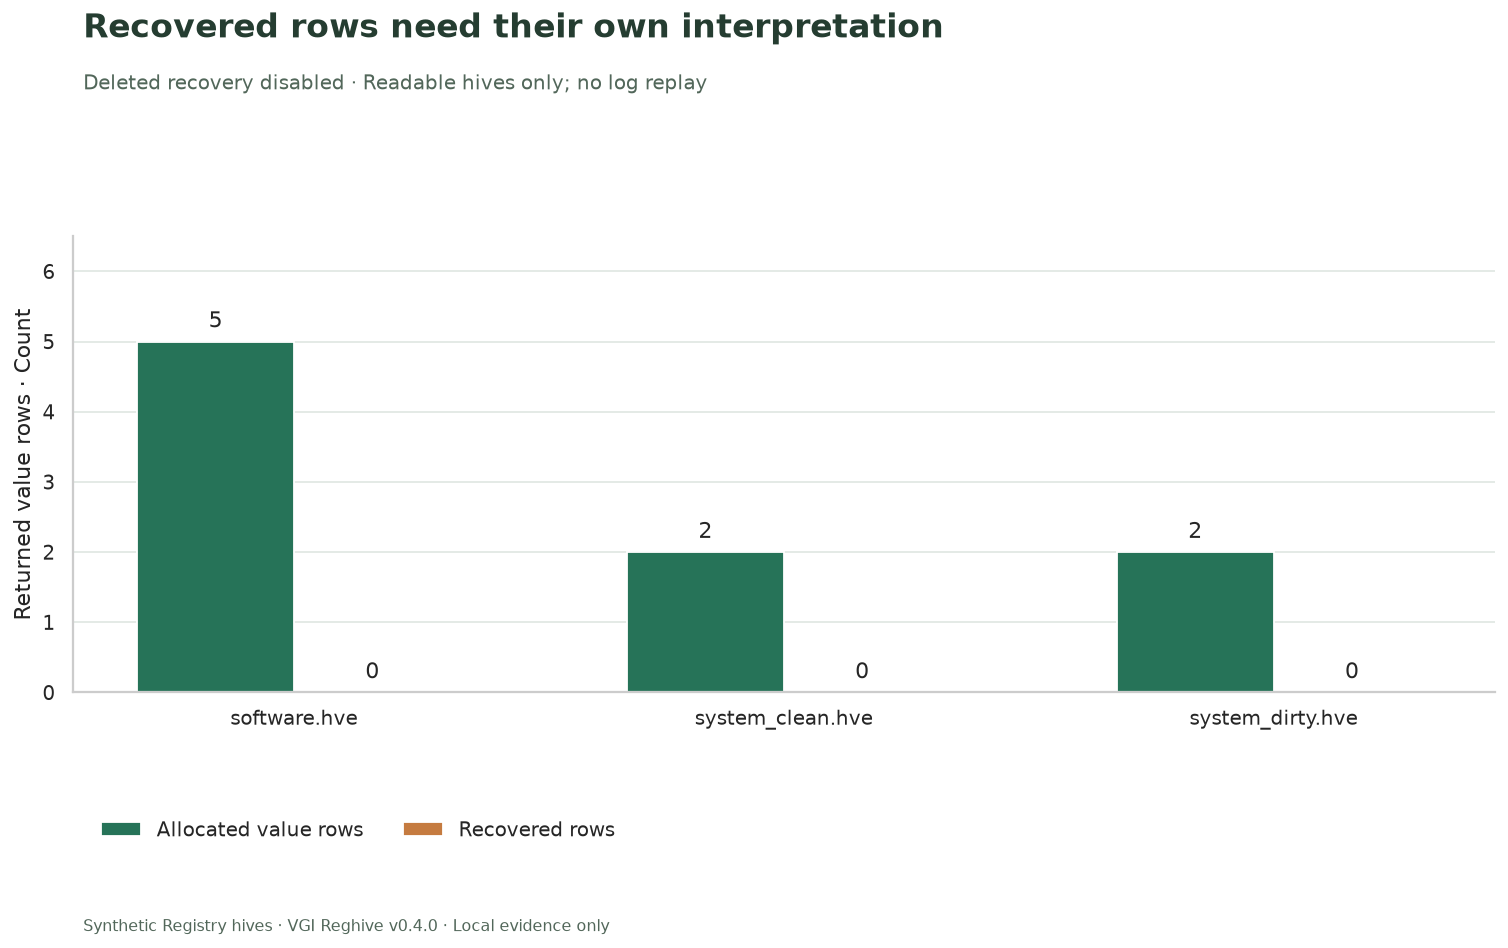

The scan returns **9 allocated value rows** and **0 recovered value rows**. The SYSTEM clean and dirty examples have matching values, but their acquisition context remains different. Recovery is disabled, so this result says nothing about whether recoverable deleted material exists.

,input_id,input_state,allocated_value_rows,recovered_value_rows,recovery_labels
0,software.hve,Clean header,5,0,0
1,system_clean.hve,Clean header,2,0,0
2,system_dirty.hve,"Dirty header, no logs",2,0,0


In [9]:
fig, ax = plt.subplots(figsize=(12, 7.4))
x = np.arange(len(summary))
width = 0.32
for shift, col, label, color in [
    (-width / 2, "allocated_value_rows", "Allocated value rows", "#267358"),
    (width / 2, "recovered_value_rows", "Recovered rows", "#c57b40"),
]:
    bars = ax.bar(x + shift, summary[col], width, label=label, color=color)
    ax.bar_label(bars, padding=5, fontsize=12)
ax.set_xticks(x, summary.input_id)
ax.set_ylabel("Returned value rows · Count")
ax.set_ylim(
    0, max(1, float(summary[["allocated_value_rows", "recovered_value_rows"]].max().max())) * 1.3
)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower left",
    bbox_to_anchor=(0.08, 0.10),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Recovered rows need their own interpretation",
    f"Deleted recovery {'enabled' if RECOVER_DELETED else 'disabled'} · Readable hives only; no log replay",
    "02_recovery_scope.png",
    bottom=0.21,
)
allocated = int(summary.allocated_value_rows.sum())
recovered = int(summary.recovered_value_rows.sum())
prose(
    f"The scan returns **{allocated} allocated value rows** and **{recovered} recovered value rows**. "
    "The SYSTEM clean and dirty examples have matching values, but their acquisition context remains different. "
    + (
        "The SOFTWARE recovery rows have two provenance labels for the fixture’s deleted Trace value; do not sum them as distinct historical settings."
        if RECOVER_DELETED
        else "Recovery is disabled, so this result says nothing about whether recoverable deleted material exists."
    )
)
display(summary)

## Check the distinctions the narrative depends on

These checks preserve input coverage, typed decoding, source-scoped joins and the
boundary between allocated and deleted rows. Fixture-specific checks document this
release's observed behavior, including the two recovery representations. They do
not promise completeness on arbitrary hives or validate transaction-log replay.

In [10]:
%%sql checks <<
SELECT 'Every supplied or missing input survives' AS check_name,
 (SELECT count(*)=6 AND count(DISTINCT input_id)=6 FROM input_audit) AS passed
UNION ALL SELECT 'Empty, malformed and missing states remain distinct',
 (SELECT count(DISTINCT input_state)=3 FROM input_audit WHERE NOT coalesce(header_ok,false))
UNION ALL SELECT 'Dirty header has unequal sequences',
 (SELECT is_dirty AND primary_seq<>secondary_seq FROM input_audit WHERE input_id='system_dirty.hve')
UNION ALL SELECT 'No supplied log was replayed',
 (SELECT bool_and(NOT logs_applied AND entries_replayed=0) FROM input_audit WHERE header_ok)
UNION ALL SELECT 'Source join preserves the value-row population',
 (SELECT count(*) FROM values_with_context)=(SELECT count(*) FROM scanned_rows WHERE value_type IS NOT NULL)
UNION ALL SELECT 'Allocated values are retained with either recovery scope',
 (SELECT count(*)=9 FROM values_with_context WHERE NOT is_deleted)
UNION ALL SELECT 'Key-only rows are excluded from value counts',
 EXISTS(SELECT 1 FROM scanned_rows WHERE value_type IS NULL)
 AND NOT EXISTS(SELECT 1 FROM values_with_context WHERE value_type IS NULL)
UNION ALL SELECT 'DWORD and QWORD retain their numeric values',
 (SELECT count(*)=2 FROM values_with_context WHERE input_id='software.hve'
 AND ((value_type='REG_DWORD' AND value_dword=2) OR (value_type='REG_QWORD' AND value_dword=18838586676582)))
UNION ALL SELECT 'Binary rendering agrees with preserved raw bytes',
 (SELECT lower(hex(value_raw))=value_data FROM values_with_context WHERE value_type='REG_BINARY')
UNION ALL SELECT 'Dirty context remains on every dirty-hive value',
 (SELECT bool_and(is_dirty AND recovery='dirty-no-logs') FROM values_with_context WHERE input_id='system_dirty.hve')
UNION ALL SELECT 'Deleted rows follow the selected scope',
 (SELECT count(*)=CASE WHEN {{ RECOVER_DELETED }} THEN 2 ELSE 0 END FROM values_with_context WHERE is_deleted)
UNION ALL SELECT 'Recovered representations retain both provenance labels',
 NOT {{ RECOVER_DELETED }} OR
 (SELECT count(DISTINCT recovery)=2 AND count(DISTINCT value_data)=1 FROM values_with_context WHERE is_deleted);

In [11]:
display(checks)
assert checks.passed.fillna(False).all(), checks.loc[~checks.passed.fillna(False)]
assert (
    allocated + recovered == con.execute("SELECT count(*) FROM values_with_context").fetchone()[0]
)
prose(
    f"**{len(checks)} SQL checks and the chart reconciliation passed.** The result accounts for returned rows; it does not establish a complete historical Registry state."
)

,check_name,passed
0,Every supplied or missing input survives,True
1,"Empty, malformed and missing states remain dis...",True
2,Dirty header has unequal sequences,True
3,No supplied log was replayed,True
4,Source join preserves the value-row population,True
5,Allocated values are retained with either reco...,True
6,Key-only rows are excluded from value counts,True
7,DWORD and QWORD retain their numeric values,True
8,Binary rendering agrees with preserved raw bytes,True
9,Dirty context remains on every dirty-hive value,True


**12 SQL checks and the chart reconciliation passed.** The result accounts for returned rows; it does not establish a complete historical Registry state.

## Experiment: enable deleted recovery

Change **`RECOVER_DELETED=False` to `True`**, restart and run all. Predict that the
input audit and allocated value counts remain unchanged while SOFTWARE gains
recovery rows. Compare the second chart and the rows' `recovery` labels, not just a
grand total. The pinned fixture yields two representations of the deleted `Trace`
value; neither should be silently merged into a current-settings table.

This experiment changes parser scope, not evidence bytes or log availability. It
cannot establish when deletion happened, prove recovery completeness or repair the
dirty hive. Reset to **`False`** to restore the saved example.

For a deeper investigation, review the worker's `hive_key`, `hive_value`, `key_info`
and `hive_subtree` functions. Use an explicit acquisition scope and retain source
and recovery provenance when combining their results.

In [12]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Notebook setup and provenance](README.md)